# Simulating the orbital variability of Cygnus X-1 with SIXTE

This tutorial shows how to simulate a source whose **spectrum changes along its orbit**, using the black-hole high-mass X-ray binary Cygnus X-1 as an example.

The SIMPUT format allows the variability of a source to be described with a light curve, a power spectrum or a photon list. Here we use a periodic **light curve in which each point refers to its own spectrum**, so that both the flux and the spectral shape change with orbital phase. SIXTE interpolates linearly between the spectra at consecutive phases.

The orbital evolution of the spectrum is based on two studies of the hard state of Cyg X-1:
* the photon index $\Gamma$ of each NICER observation and its orbital phase, from [König et al. (2024, A&A 687, A284)](https://doi.org/10.1051/0004-6361/202449333), Table C.1;
* the average column density $N_\mathrm{H}$ as a function of orbital phase, from the RXTE monitoring of [Grinberg et al. (2015, A&A 576, A117)](https://doi.org/10.1051/0004-6361/201425418), Fig. 6.

Orbital phase 0 is the superior conjunction of the black hole, where the line of sight crosses the densest part of the stellar wind.

**Workflow**
1. Read the table and build the phase-dependent model (hard state only, binned in phase).
2. Create one XSPEC model and one SIMPUT spectrum per phase.
3. Merge the spectra and build the time-variable SIMPUT file (`LIGHTCURVE` extension).
4. Simulate short X-IFU observations starting at different orbital phases with `sixtesim`, with **several statistical realizations** per phase.
5. Extract and fit the phase-resolved spectra, with all valid events and with the high-resolution events only, and compare the recovered $N_\mathrm{H}$ and $\Gamma$ with the input, including the **scatter between realizations** and the **bias** (recovered − input).
6. Simulated spectra, light curve, hardness ratio and event grades from the event files.
7. *(Optional)* How the uncertainties depend on the exposure time.

In [1]:
import os, re, glob, shutil, subprocess, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
from astropy.io import fits
from astropy.table import Table

### Plot style

All figures share the same style: serif fonts that match a LaTeX document, inward ticks on all sides, minor ticks and no grid. The colors are defined once here.

In [2]:
plt.rcParams.update({
    "font.family": "serif", "mathtext.fontset": "cm", "font.size": 10,
    "axes.labelsize": 10, "legend.fontsize": 8, "legend.frameon": False,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True,
    "xtick.minor.visible": True, "ytick.minor.visible": True,
    "axes.linewidth": 0.8, "lines.linewidth": 1.2, "savefig.bbox": "tight", "savefig.dpi": 300,
})
COL = {"model": "#1B2A5C",    # input model (navy)
       "rxte": "#3A7D44",     # RXTE N_H (green)
       "nicer": "#704080",    # NICER Gamma (violet)
       "sim": "#8B1E2D",      # recovered from the simulation (garnet)
       "soft": "#1B2A5C", "hard": "#8B1E2D"}

def phase_axis(ax):
    # common formatting of an orbital-phase axis
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_locator(MultipleLocator(0.2))
    ax.xaxis.set_minor_locator(AutoMinorLocator(4))

def panel_label(ax, s, pad=0.2):
    # panel letter in the upper-left corner; the y range is extended so that it does not overlap the data
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi + pad * (hi - lo))
    ax.text(0.015, 0.96, s, transform=ax.transAxes, va="top", ha="left")

## 0. Configuration

Everything you may need to change is in this cell.

* `TABLE_FILE`: CSV with Table C.1 of König et al. (2024): `obsid, phi_start, phi_end, gamma, state, ...`. The `state` column (`hard` for $\Gamma \le 2$) is used if present; otherwise the hard state is selected with $\Gamma \le$ `GAMMA_MAX`.
* `NH_FILE`: average hard-state column density versus orbital phase, digitized from Fig. 6 of Grinberg et al. (2015), `phase, nH` (in $10^{22}$ cm$^{-2}$, including the interstellar absorption).
* `XMLDIR`, `XMLFILE`: X-IFU instrument files of your SIXTE installation (list them with `ls $SIXTE/share/sixte/instruments/athena-xifu`). For a bright source like Cyg X-1 a defocused configuration is advisable.
* `N_REAL`: number of statistical realizations (different random seeds) per phase. With a single realization, the difference between recovered and input values cannot be separated from Poisson noise.
* Check the `sixtesim` parameters of your version with `plist sixtesim`.

In [3]:
# --- input tables ---
TABLE_FILE = "koenig2024_tableC1.csv"    # Gamma and orbital phase per NICER observation (König et al. 2024, Table C.1)
NH_FILE = "grinberg2015_nH_hard.csv"      # hard-state N_H vs orbital phase (Grinberg et al. 2015, Fig. 6)
USE_HARD_STATE_ONLY = True       # separate orbital modulation from state changes
GAMMA_MAX = 2.0                  # hard-state criterion if there is no 'state' column

# --- source ---
RA, DEC = 299.59, 35.20          # Cyg X-1
P_ORB_DAYS = 5.599829            # orbital period [d]; use the ephemeris adopted by König et al. (2024)
P_ORB = P_ORB_DAYS * 86400.      # [s]
FLUX_REF = 1.0e-8                # 2-10 keV flux [erg/cm2/s] of the spectrum at phase 0 (representative of the hard state)
EMIN_FLUX, EMAX_FLUX = 2.0, 10.0

# --- SIMPUT energy grid (X-IFU needs a linear grid; 1 eV bins) ---
ELOW, EUP = 0.1, 15.0
NBINS = int(round((EUP - ELOW) / 0.001))

# --- simulation ---
SIXTE = os.environ.get("SIXTE", "")
SIMPUT_DIR = os.environ.get("SIMPUT", SIXTE)
XMLDIR = "/Users/jessicaplanelles/Desktop/new-athena-xifu/baseline"   # [CHECK] adapt to your installation
XMLFILE = os.path.join(XMLDIR, "xifu_nofilt_defoc.xml")              # defocused, no filter
MJDREF = 55000.0                 # same MJDREF in the SIMPUT light curve and in sixtesim
SIM_PHASES = np.linspace(0.05, 0.95, 10)   # orbital phases at which the observations start
EXPOSURE = 500.                  # [s] per observation (~5000 cts/s with the defocused X-IFU)
N_REAL = 5                       # statistical realizations per phase (different seeds)
REUSE_EVENTS = True              # do not re-simulate event files that already exist

# --- analysis ---
FIT_BAND = (0.5, 10.0)           # [keV]
SOFT, HARD = (0.5, 2.0), (2.0, 10.0)
ALL_FILTER = None                # all valid events (used for the continuum fits)
HR_FILTER = "GRADING==1"         # high-resolution events [CHECK the grade value in your XML file]

# --- optional: dependence on exposure time (Sect. 7) ---
RUN_EXPOSURE_TEST = False
TEST_PHASE = 0.05                # phase of the test (near superior conjunction: highest N_H)
TEST_EXPOSURES = [50., 100., 250., 500., 1000.]   # [s]

WORKDIR = os.path.abspath("/Volumes/JESS/cygx1_1")
TMPDIR = os.path.join(WORKDIR, "tmp")
FIGDIR = os.path.join(WORKDIR, "figures")
for d in (TMPDIR, FIGDIR):
    os.makedirs(d, exist_ok=True)

ENV = os.environ.copy()
ENV["HEADASNOQUERY"] = "true"
print("Working directory:", WORKDIR)

Working directory: /Volumes/JESS/cygx1_1


## 1. Phase-dependent spectral model

### 1.1 Read Table C.1 of König et al. (2024) and assign $N_\mathrm{H}$

Each NICER observation covers a range of orbital phases; we use its midpoint, taking into account that some observations cross phase 0 (e.g. 0.94–0.04). The column density at that phase is interpolated from the hard-state averages of Grinberg et al. (2015).

In [4]:
tab = Table.read(TABLE_FILE, format="ascii.csv")
nh_tab = Table.read(NH_FILE, format="ascii.csv", comment="#")

def circ_interp(x, xp, fp):
    # linear interpolation of a periodic function of the orbital phase
    xp, fp = np.asarray(xp, float), np.asarray(fp, float)
    return np.interp(x, np.concatenate([xp - 1, xp, xp + 1]), np.tile(fp, 3))

def mid_phase(p0, p1):
    # midpoint of a phase interval, also for intervals that cross phase 0
    p0, p1 = np.asarray(p0, float) % 1, np.asarray(p1, float) % 1
    width = (p1 - p0) % 1
    return (p0 + width / 2) % 1

tab["phase"] = mid_phase(tab["phi_start"], tab["phi_end"])

if USE_HARD_STATE_ONLY:
    if "state" in tab.colnames:
        sel = np.char.lower(np.asarray(tab["state"], str)) == "hard"
    else:
        sel = np.asarray(tab["gamma"]) <= GAMMA_MAX
    tab = tab[sel]
tab["nH"] = circ_interp(tab["phase"], nh_tab["phase"], nh_tab["nH"])
print(f"{len(tab)} observations selected")
tab.sort("phase")
tab["obsid", "phase", "gamma", "nH"].pprint(max_lines=-1)

31 observations selected
  obsid           phase         gamma         nH        
---------- -------------------- ----- ------------------
4690010103 0.004999999999999893   1.7 2.0709999999999997
4690010109                0.005   1.6              2.071
4690010111 0.010000000000000009   1.6              2.082
 100320101                0.025   1.8 2.1149999999999998
 100320106                 0.07   1.8              2.068
1100320116                 0.09   1.7              1.966
 100320107  0.22999999999999998   2.0                1.3
4690020105                 0.45   1.7               0.91
1100320112  0.46499999999999997   1.8             0.9115
4690020103                 0.48   1.7              0.913
4690020107                0.485   1.6             0.9135
4690020104                0.485   1.7             0.9135
4690020110                 0.49   1.7              0.914
4690020101                0.495   1.6             0.9145
4690020102                0.495   1.6             0.9145
469002

### 1.2 Phase grid

The spectra are defined on the phase bins of Grinberg et al. (2015), so that the orbital modulation of $N_\mathrm{H}$ is kept. In each bin, $\Gamma$ is the mean of the NICER hard-state observations falling in it; bins without observations take the value interpolated from the neighboring bins. The light curve must be defined on strictly increasing phases, and we add the two ends (phase 0 and 1, with the same parameters) so that the interpolation is continuous across phase 0.

In [5]:
ph = np.asarray(nh_tab["phase"], float)
nh = np.asarray(nh_tab["nH"], float)
half = 0.5 * np.min(np.diff(ph))
gam, nobs = np.full(len(ph), np.nan), np.zeros(len(ph), int)
dphi = (np.asarray(tab["phase"])[:, None] - ph[None, :] + 0.5) % 1 - 0.5   # circular distance to bin centers
for k in range(len(ph)):
    m = np.abs(dphi[:, k]) < half
    nobs[k] = m.sum()
    if nobs[k]:
        gam[k] = np.mean(tab["gamma"][m])
ok = np.isfinite(gam)
gam[~ok] = circ_interp(ph[~ok], ph[ok], gam[ok])
print("NICER observations per bin:", nobs)

g0, n0 = circ_interp(0.0, ph, gam), circ_interp(0.0, ph, nh)
phases = np.concatenate([[0.0], ph, [1.0]])
gammas = np.concatenate([[g0], gam, [g0]])
nHs = np.concatenate([[n0], nh, [n0]])

for p, g, n in zip(phases, gammas, nHs):
    print(f"phase {p:5.3f}   Gamma {g:5.3f}   nH {n:6.3f} 1e22 cm^-2")

NICER observations per bin: [6 0 1 0 8 1 1 2 5 7]
phase 0.000   Gamma 1.671   nH  2.060 1e22 cm^-2
phase 0.050   Gamma 1.700   nH  2.170 1e22 cm^-2
phase 0.150   Gamma 1.850   nH  1.660 1e22 cm^-2
phase 0.250   Gamma 2.000   nH  1.210 1e22 cm^-2
phase 0.350   Gamma 1.837   nH  1.130 1e22 cm^-2
phase 0.450   Gamma 1.675   nH  0.910 1e22 cm^-2
phase 0.550   Gamma 1.600   nH  0.920 1e22 cm^-2
phase 0.650   Gamma 1.700   nH  0.910 1e22 cm^-2
phase 0.750   Gamma 1.850   nH  1.160 1e22 cm^-2
phase 0.850   Gamma 1.740   nH  1.470 1e22 cm^-2
phase 0.950   Gamma 1.643   nH  1.950 1e22 cm^-2
phase 1.000   Gamma 1.671   nH  2.060 1e22 cm^-2


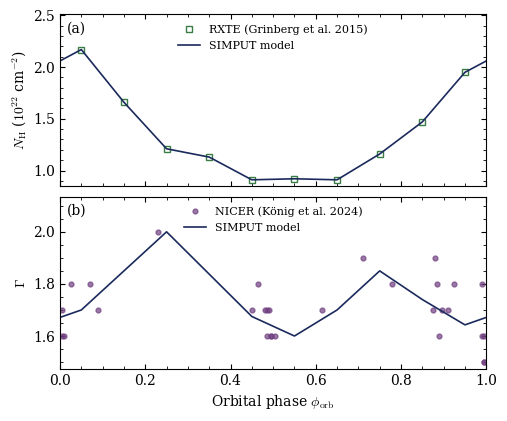

In [6]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(5.5, 4.6), gridspec_kw={"hspace": 0.06})
ax[0].plot(nh_tab["phase"], nh_tab["nH"], "s", ms=5, mfc="none", mec=COL["rxte"], mew=1.0,
           label="RXTE (Grinberg et al. 2015)")
ax[0].plot(phases, nHs, "-", color=COL["model"], label="SIMPUT model")
ax[1].plot(tab["phase"], tab["gamma"], "o", ms=3.5, color=COL["nicer"], alpha=0.7,
           label="NICER (König et al. 2024)")
ax[1].plot(phases, gammas, "-", color=COL["model"], label="SIMPUT model")
ax[0].set_ylabel(r"$N_\mathrm{H}$ ($10^{22}$ cm$^{-2}$)")
ax[1].set_ylabel(r"$\Gamma$")
ax[1].set_xlabel(r"Orbital phase $\phi_\mathrm{orb}$")
for a, s in zip(ax, "ab"):
    phase_axis(a); panel_label(a, f"({s})"); a.legend(loc="upper center")
fig.savefig(os.path.join(FIGDIR, "cygx1_input_model.pdf"))
plt.show()

### 1.3 Create one XSPEC model per phase

Each model is an absorbed power law, `TBabs*powerlaw`, with the abundances of Wilms et al. (2000) and the cross sections of Verner et al. (1996), as in Grinberg et al. (2015). All models have the same normalization, so their 2–10 keV fluxes change with $\Gamma$ and $N_\mathrm{H}$; these fluxes give the relative flux of the light curve. PyXspec is used if available; otherwise the commands are passed to XSPEC directly.

In [7]:
def create_xcm_pyxspec(gamma, nH, filename):
    xs.Xset.abund = "wilm"; xs.Xset.xsect = "vern"
    xs.AllModels.clear()
    m = xs.Model("TBabs*powerlaw")
    m.TBabs.nH = nH; m.powerlaw.PhoIndex = gamma; m.powerlaw.norm = 1.0
    xs.AllModels.calcFlux(f"{EMIN_FLUX} {EMAX_FLUX}")
    flux = xs.AllModels(1).flux[0]
    if os.path.exists(filename):
        os.remove(filename)
    xs.Xset.save(filename, info="m")
    return flux

def create_xcm_manual(gamma, nH, filename):
    if os.path.exists(filename):
        os.remove(filename)
    cmds = ["abund wilm", "xsect vern", "model TBabs*powerlaw", f"{nH}", f"{gamma}", "1.0",
            f"flux {EMIN_FLUX} {EMAX_FLUX}", f"save model {filename}", "exit"]
    out = subprocess.run(["xspec"], input="\n".join(cmds) + "\n", text=True,
                         capture_output=True).stdout
    mt = re.search(r"Model Flux\s+.*\(([\d\.eE\-\+]+)\s+ergs/cm\^2/s", out)
    if mt is None:
        raise RuntimeError("No flux found in the XSPEC output:\n" + out)
    return float(mt.group(1))

try:
    import xspec as xs
    xs.Xset.chatter = 0
    create_xcm = create_xcm_pyxspec
    print("Using PyXspec")
except ImportError:
    create_xcm = create_xcm_manual
    print("PyXspec not available, calling XSPEC directly")

# the last point (phase 1) has the same spectrum as phase 0: only len(phases)-1 spectra are needed
nspec = len(phases) - 1
xcm_files, model_fluxes = [], []
for i in range(nspec):
    f = os.path.join(TMPDIR, f"cygx1_phase_{i:02d}.xcm")
    model_fluxes.append(create_xcm(gammas[i], nHs[i], f))
    xcm_files.append(f)
model_fluxes = np.array(model_fluxes)
rel_fluxes = np.concatenate([model_fluxes / model_fluxes[0], [1.0]])
print("Relative 2-10 keV flux:", np.round(rel_fluxes, 3))

Using PyXspec
Relative 2-10 keV flux: [1.    0.95  0.768 0.624 0.807 1.056 1.189 1.014 0.79  0.923 1.053 1.   ]


## 2. One SIMPUT spectrum per phase with `simputfile`

The X-IFU requires a linear energy grid; we use 1 eV bins between 0.1 and 15 keV. The flux of each file is not important, except for the first one, which sets the reference flux of the source catalog (`FLUX_REF`); the flux at the other phases is set by the light curve.

In [8]:
simput_files = []
for i, xcm in enumerate(xcm_files):
    out = os.path.join(TMPDIR, f"cygx1_phase_{i:02d}.simput")
    cmd = [os.path.join(SIMPUT_DIR, "bin", "simputfile"),
           f"XSPECFile={xcm}", f"Simput={out}",
           f"Elow={ELOW}", f"Eup={EUP}", f"Nbins={NBINS}", "logEgrid=no",
           f"Emin={EMIN_FLUX}", f"Emax={EMAX_FLUX}", f"srcFlux={FLUX_REF * rel_fluxes[i]}",
           f"RA={RA}", f"Dec={DEC}", "clobber=yes", "chatter=1"]
    subprocess.run(cmd, check=True, env=ENV)
    simput_files.append(out)
print(f"{len(simput_files)} SIMPUT files created")


		XSPEC version: 12.15.1
	Build Date/Time: Wed May  6 17:15:08 2026


!XSPEC12>method leven 10 0.01

!XSPEC12>abund wilm
 Solar Abundance Vector set to wilm:  Wilms, J., Allen, A. & McCray, R. ApJ 542 914 (2000) (abundances are set to zero for those elements not included in the paper).

!XSPEC12>xsect vern
 Cross Section Table set to vern:  Verner, Ferland, Korista, and Yakovlev 1996

!XSPEC12>cosmo 70 0 0.73

!XSPEC12>xset delta 0.01
Parameter delta values for fits will now be 0.01 * parValue

!XSPEC12>xset APECROOT  3.1.3

!XSPEC12>xset NEIAPECROOT  3.1.3

!XSPEC12>xset SPEXROOT  3.08

!XSPEC12>xset TBABSVERSION  2.0

!XSPEC12>systematic 0

 The default systematic error for models is set to 0


!XSPEC12>model  TBabs*powerlaw  ;             2.06      0.001          0          0     100000      1e+06  ;          1.67143       0.01         -3         -2          9         10  ;                1       0.01          0          0      1e+20      1e+24

Model TBabs<1>*powerlaw<2> Source No

## 3. Build the time-variable SIMPUT file

### 3.1 Merge all the spectra with `simputmerge`

In [9]:
merged = os.path.join(TMPDIR, "cygx1_all_spectra.simput")
cmd = [os.path.join(SIMPUT_DIR, "bin", "simputmerge"), ",".join(simput_files),
       "FetchExtensions=yes", merged]
subprocess.run(cmd, input="yes\n", text=True, env=ENV, check=True)
with fits.open(merged) as h:
    print("Spectra in the merged file:", len(h["SPECTRUM"].data))


merging simput files ...
100%

cleaning up ...
finished successfully!

Spectra in the merged file: 11


### 3.2 Assemble the time-variable SIMPUT file

The file contains three extensions:

* `SRC_CAT`: the source catalog of the first phase. Its `TIMING` column points to the light curve, and its `SPECTRUM` column to the spectrum of phase 0. This column must **not** be `NULL`: SIXTE uses this spectrum as the reference to convert the catalog flux into a photon rate (with `NULL` the simulation stops with `Assertion failed: (avgrate>0.)`).
* `LIGHTCURVE`: periodic light curve with the columns `PHASE` (orbital phase), `FLUX` (flux relative to the catalog) and `SPECTRUM` (row of the `SPECTRUM` extension valid at that phase). Phase 0 corresponds to `TIMEZERO`, i.e. to time 0 of the simulation (relative to `MJDREF`).
* `SPECTRUM`: all the spectra, copied from the merged file.

**Note:** the `SPECTRUM` extension has variable-length columns. Copying it with astropy can corrupt them (in some rows the energy grid is replaced by other values), so it is appended with the HEASoft tool `ftappend`, and the result is checked.

In [10]:
simput_var = os.path.join(WORKDIR, "cygx1_orbital_variability.simput")

# SRC_CAT (one source) and LIGHTCURVE: no variable-length columns, safe to write with astropy
with fits.open(simput_files[0]) as h0:
    src = fits.BinTableHDU(data=h0["SRC_CAT"].data.copy(), header=h0["SRC_CAT"].header.copy(), name="SRC_CAT")
src.data["SPECTRUM"] = "[SPECTRUM,1][#row==1]"
src.data["TIMING"] = "[LIGHTCURVE,1]"

spec_rows = list(range(1, nspec + 1)) + [1]      # phase 1 uses the spectrum of phase 0
spec_refs = np.array([f"[SPECTRUM,1][#row=={r}]" for r in spec_rows], dtype="S100")
lc = fits.BinTableHDU.from_columns([
    fits.Column(name="PHASE", format="E", array=phases.astype(np.float32)),
    fits.Column(name="FLUX", format="E", array=rel_fluxes.astype(np.float32)),
    fits.Column(name="SPECTRUM", format="100A", array=spec_refs)], name="LIGHTCURVE")
hdr = lc.header
hdr["HDUCLASS"] = "HEASARC/SIMPUT"; hdr["HDUCLAS1"] = "LIGHTCURVE"; hdr["HDUVERS"] = "1.1.0"
hdr["EXTVER"] = 1
hdr["MJDREF"] = MJDREF; hdr["TIMEZERO"] = 0.0
hdr["PERIODIC"] = 1; hdr["PHASE0"] = 0.0; hdr["PERIOD"] = P_ORB
hdr["FLUXSCAL"] = 1.0

fits.HDUList([fits.PrimaryHDU(), src, lc]).writeto(simput_var, overwrite=True)

# SPECTRUM: appended with cfitsio (ftappend), which handles variable-length columns correctly
subprocess.run(["ftappend", f"{merged}[SPECTRUM]", simput_var], check=True, env=ENV)

CompletedProcess(args=['ftappend', '/Volumes/JESS/cygx1_1/tmp/cygx1_all_spectra.simput[SPECTRUM]', '/Volumes/JESS/cygx1_1/cygx1_orbital_variability.simput'], returncode=0)

### 3.3 Check the time-variable SIMPUT file

Every spectrum must cover the same energy grid (0.1–15 keV) and have a positive flux.

In [11]:
with fits.open(simput_var) as h:
    h.info()
    print(Table(h["SRC_CAT"].data)["SRC_ID", "FLUX", "SPECTRUM", "TIMING"])
    print(Table(h["LIGHTCURVE"].data))
    for i, r in enumerate(h["SPECTRUM"].data, start=1):
        e, f = np.asarray(r["ENERGY"]), np.asarray(r["FLUXDENSITY"])
        print(f"row {i:2d}  {r['NAME']}:  E = {e.min():.3f}-{e.max():.3f} keV,  {len(e)} bins")
        assert abs(e.min() - ELOW) < 0.01 and abs(e.max() - EUP) < 0.01, f"spectrum {i} is corrupted"
        assert np.all(np.isfinite(f)) and f.sum() > 0, f"spectrum {i} has no valid flux"
print("All spectra OK")

Filename: /Volumes/JESS/cygx1_1/cygx1_orbital_variability.simput
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  SRC_CAT       1 BinTableHDU     44   1R x 12C   [J, 32A, D, D, E, E, E, E, E, 32A, 32A, 32A]   
  2  LIGHTCURVE    1 BinTableHDU     25   12R x 3C   [E, E, 100A]   
  3  SPECTRUM      1 BinTableHDU     21   11R x 3C   [1PE(14900), 1PE(14900), 48A]   
SRC_ID  FLUX        SPECTRUM           TIMING    
------ ----- --------------------- --------------
     1 1e-08 [SPECTRUM,1][#row==1] [LIGHTCURVE,1]
PHASE    FLUX           SPECTRUM       
----- ---------- ----------------------
  0.0        1.0  [SPECTRUM,1][#row==1]
 0.05  0.9495843  [SPECTRUM,1][#row==2]
 0.15 0.76779693  [SPECTRUM,1][#row==3]
 0.25  0.6244125  [SPECTRUM,1][#row==4]
 0.35 0.80684286  [SPECTRUM,1][#row==5]
 0.45  1.0555408  [SPECTRUM,1][#row==6]
 0.55  1.1894305  [SPECTRUM,1][#row==7]
 0.65  1.0144306  [SPECTRUM,1][#row==8]
 0.75 0.78986585

## 4. Simulate X-IFU observations at different orbital phases with `sixtesim`

A single observation covering the whole 5.6 d orbit would be very long to simulate. Instead, we run several short observations, each starting at a different orbital phase: with phase 0 at time 0, an observation starting at phase $\phi$ has `TSTART` $=\phi\,P_\mathrm{orb}$.

Each observation is repeated `N_REAL` times with different random seeds. The mean of the realizations shows whether the input is recovered without bias, and their scatter gives the statistical uncertainty expected for a single observation. Event files that already exist and contain an `EVENTS` extension are reused; incomplete files from failed runs are removed and simulated again.

In [ ]:
def valid_evt(path):
    # True if the file exists and contains an EVENTS extension
    try:
        with fits.open(path) as h:
            return "EVENTS" in h
    except Exception:
        return False

def run_sixtesim(phi, exposure, seed, tag="", retries=1):
    evt = os.path.join(WORKDIR, f"cygx1_evt_phase{phi:.3f}{tag}_s{seed:03d}.fits")
    if REUSE_EVENTS and valid_evt(evt):
        return evt
    cmd = [os.path.join(SIXTE, "bin", "sixtesim"),
           f"XMLFile={XMLFILE}", f"Simput={simput_var}", f"EvtFile={evt}",
           f"RA={RA}", f"Dec={DEC}", f"MJDREF={MJDREF}",
           f"TSTART={phi * P_ORB}", f"Exposure={exposure}",
           f"Seed={seed}", "clobber=yes", "chatter=0"]
    for attempt in range(retries + 1):
        if os.path.exists(evt):
            os.remove(evt)                       # remove partial files from failed runs
        p = subprocess.run(cmd, env=ENV, capture_output=True, text=True, cwd=WORKDIR)
        if p.returncode == 0 and valid_evt(evt):
            return evt
    raise RuntimeError(f"sixtesim failed for phase {phi:.3f}, seed {seed}:\n{p.stderr[-2000:]}")

evt_files = {}      # (phase index, realization) -> event file
t0 = time.time()
for k, phi in enumerate(SIM_PHASES):
    for r in range(N_REAL):
        evt_files[k, r] = run_sixtesim(phi, EXPOSURE, seed=1 + k * N_REAL + r)
    print(f"phase {phi:.3f}: {N_REAL} realizations done ({time.time() - t0:.0f} s elapsed)")

phase 0.050: 5 realizations done (884 s elapsed)


The `GRADING` column gives the grade of each event, which depends on the time separation from the previous and next events in the same pixel. The grade numbers and the corresponding response files are defined in the instrument XML file (`grep -i grading $XMLFILE`); check which value corresponds to the highest resolution in your installation before setting `HR_FILTER`.

In [ ]:
with fits.open(evt_files[0, 0]) as h:
    h.info()
    d = h["EVENTS"].data
    print("\nColumns:", d.columns.names)
    print("Events:", len(d))
    g, n = np.unique(d["GRADING"], return_counts=True)
    for gi, ni in zip(g, n):
        print(f"  GRADING = {gi:3d}: {ni:9d} events ({100 * ni / len(d):5.1f}%)")

## 5. Phase-resolved spectra

### 5.1 Extract the spectra with `makespec`

Two spectra are extracted from each observation: one with **all valid events** and one with the **high-resolution events only**. No spatial selection is applied: the simulation contains a single source, and with the defocused configuration its photons are spread over many pixels. Photons reflected by different mirror shells land at different distances from the center of the defocused spot and have different energy distributions, so the spectrum depends on which pixels are selected.

The same effect makes the high-resolution events a biased subsample for a bright source. The count rate per pixel is highest near the center of the spot, where the spectrum is also hardest, so more of the hard photons arrive too close in time to a neighbor to be classified as high-resolution events. A continuum fit to the high-resolution events alone therefore returns a spectrum that is too soft, by an amount that grows with the count rate. For the continuum, which does not need the best energy resolution, all valid events should be used.

In [ ]:
SELECTIONS = {"all": ALL_FILTER, "hr": HR_FILTER}
SEL_LABEL = {"all": "All valid events", "hr": "High-resolution events only"}

def extract_spectrum(evt, flt, tag):
    pha = evt.replace("_evt_", f"_spec{tag}_").replace(".fits", ".pha")
    cmd = [os.path.join(SIXTE, "bin", "makespec"), f"EvtFile={evt}", f"Spectrum={pha}",
           f"RSPPath={XMLDIR}", "clobber=yes"]
    if flt:
        cmd.append(f"EventFilter={flt}")
    subprocess.run(cmd, check=True, env=ENV, stdout=subprocess.DEVNULL)
    return pha

pha_files = {(sel, k, r): extract_spectrum(evt, flt, sel)
             for sel, flt in SELECTIONS.items() for (k, r), evt in evt_files.items()}
print(f"{len(pha_files)} spectra extracted")

### 5.2 Fit each spectrum with the input model

The spectra are fitted with the same absorbed power law (PyXspec required), using the C-statistic and 68% (1$\sigma$) confidence intervals. The input value of each observation is the average of the input model over the exposure, using the same linear interpolation that SIXTE applies between phases.

In [ ]:
import xspec as xs
from xspec import AllData, AllModels, Fit, Xset
Xset.abund = "wilm"; Xset.xsect = "vern"; Xset.chatter = 0
Fit.statMethod = "cstat"; Fit.query = "yes"

def fit_spectrum(pha):
    # returns nH, nH_lo, nH_hi, Gamma, G_lo, G_hi
    AllData.clear(); AllModels.clear()
    cwd = os.getcwd(); os.chdir(os.path.dirname(pha))      # response files are referenced relative to the PHA
    s = xs.Spectrum(os.path.basename(pha)); os.chdir(cwd)
    s.ignore(f"**-{FIT_BAND[0]} {FIT_BAND[1]}-**")
    m = xs.Model("TBabs*powerlaw")
    Fit.perform()
    Fit.error("1.0 1 2")
    return (m.TBabs.nH.values[0], *m.TBabs.nH.error[:2],
            m.powerlaw.PhoIndex.values[0], *m.powerlaw.PhoIndex.error[:2])

def input_average(phi, exposure, y):
    # average of the input parameter y over an observation starting at phase phi
    pp = (phi + np.linspace(0, exposure / P_ORB, 101)) % 1
    return np.mean(np.interp(pp, phases, y))

phi_mid = (SIM_PHASES + EXPOSURE / P_ORB / 2) % 1
nh_in = np.array([input_average(p, EXPOSURE, nHs) for p in SIM_PHASES])
g_in = np.array([input_average(p, EXPOSURE, gammas) for p in SIM_PHASES])

fits_all, stats = {}, {}
for sel in SELECTIONS:
    fits_all[sel] = np.array([[fit_spectrum(pha_files[sel, k, r]) for r in range(N_REAL)]
                              for k in range(len(SIM_PHASES))])      # shape (n_phase, N_REAL, 6)
    st = {}
    for name, col, yin in (("nH", 0, nh_in), ("G", 3, g_in)):
        v = fits_all[sel][:, :, col]
        st[name] = dict(mean=v.mean(1), scat=v.std(1, ddof=1) if N_REAL > 1 else np.zeros(len(v)),
                        err=(0.5 * (fits_all[sel][:, :, col + 2] - fits_all[sel][:, :, col + 1])).mean(1),
                        bias=v.mean(1) - yin)
    stats[sel] = st

for sel in SELECTIONS:
    print(f"\n{SEL_LABEL[sel]}")
    print(" phase |  nH in   nH out  scatter |  G in   G out  scatter")
    s = stats[sel]
    for i in range(len(SIM_PHASES)):
        print(f" {phi_mid[i]:.3f} | {nh_in[i]:6.3f}  {s['nH']['mean'][i]:6.3f}  {s['nH']['scat'][i]:6.3f} |"
              f" {g_in[i]:5.3f}  {s['G']['mean'][i]:5.3f}  {s['G']['scat'][i]:6.3f}")
    print(f" mean bias: nH {np.mean(s['nH']['bias']):+.3f} 1e22 cm^-2,  Gamma {np.mean(s['G']['bias']):+.3f}")

### 5.3 Recovered versus input parameters

The upper panels compare the recovered parameters with the input model; the lower panels show their difference. Points are the mean of the realizations, with error bars equal to the scatter between them. Filled circles use all valid events, open squares only the high-resolution events.

In [ ]:
STY = {"all": dict(fmt="o", ms=4.5, color=COL["sim"], mfc=COL["sim"]),
       "hr": dict(fmt="s", ms=4.5, color=COL["nicer"], mfc="white")}
fig, ax = plt.subplots(4, 1, sharex=True, figsize=(5.5, 6.4),
                       gridspec_kw={"height_ratios": [3, 1.4, 3, 1.4], "hspace": 0.06})
pp = np.linspace(0, 1, 500)
for a, d, name, ymod, lab, dlab in ((ax[0], ax[1], "nH", nHs, r"$N_\mathrm{H}$ ($10^{22}$ cm$^{-2}$)", r"$\Delta N_\mathrm{H}$"),
                                    (ax[2], ax[3], "G", gammas, r"$\Gamma$", r"$\Delta\Gamma$")):
    a.plot(pp, np.interp(pp, phases, ymod), color=COL["model"], label="Input model")
    d.axhline(0, color=COL["model"], lw=0.8)
    for sel, dx in (("all", -0.006), ("hr", 0.006)):
        s = stats[sel][name]
        a.errorbar(phi_mid + dx, s["mean"], yerr=s["scat"], capsize=2, elinewidth=1,
                   label=SEL_LABEL[sel], **STY[sel])
        d.errorbar(phi_mid + dx, s["bias"], yerr=s["scat"], capsize=2, elinewidth=1, **STY[sel])
    a.set_ylabel(lab); d.set_ylabel(dlab)
for a in ax:
    phase_axis(a)
panel_label(ax[0], "(a)", pad=0.35); panel_label(ax[2], "(b)", pad=0.35)
ax[0].legend(loc="upper center", ncol=1)
ax[3].set_xlabel(r"Orbital phase $\phi_\mathrm{orb}$")
fig.align_ylabels(ax)
fig.savefig(os.path.join(FIGDIR, "cygx1_recovered_parameters.pdf"))
plt.show()

## 6. Simulated spectra, light curve, hardness ratio and event grades

The event files can also be analyzed directly. The reconstructed energies (`SIGNAL`, in keV) give the count spectrum and the count rates in a soft and a hard band, and the arrival times give the orbital phase of each event.

### 6.1 Count spectra at three orbital phases

The count spectra of all valid events show directly how the absorption changes along the orbit.

In [ ]:
def hr_mask(d):
    # high-resolution events, from HR_FILTER of the form "GRADING==n"
    g = int(HR_FILTER.split("==")[1])
    return d["GRADING"] == g

show = [int(np.argmin(np.abs(phi_mid - p))) for p in (0.0, 0.25, 0.5)]   # closest simulated phases
ebins = np.geomspace(0.5, 10.0, 120)
emid, ewid = np.sqrt(ebins[1:] * ebins[:-1]), np.diff(ebins)
cols = [COL["model"], COL["nicer"], COL["sim"]]

fig, ax = plt.subplots(figsize=(5.5, 3.8))
for i, c in zip(show, cols):
    with fits.open(evt_files[i, 0]) as h:
        e = h["EVENTS"].data["SIGNAL"]
    rate = np.histogram(e, ebins)[0] / EXPOSURE / ewid
    ax.step(emid, rate, where="mid", color=c, lw=1,
            label=rf"$\phi_\mathrm{{orb}}={phi_mid[i]:.2f}$ ($N_\mathrm{{H}}={nh_in[i]:.1f}\times10^{{22}}$ cm$^{{-2}}$)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(ebins[0], ebins[-1])
ax.set_xlabel("Energy (keV)"); ax.set_ylabel(r"Count rate (counts s$^{-1}$ keV$^{-1}$)")
ax.legend(loc="lower right")
fig.savefig(os.path.join(FIGDIR, "cygx1_count_spectra.pdf"))
plt.show()

### 6.2 Light curve, hardness ratio and fraction of high-resolution events

The lower panel shows the bias of the photon index fitted to the high-resolution events against their fraction: the fewer high-resolution events, the larger the bias.

In [ ]:
rows = np.zeros((len(SIM_PHASES), N_REAL, 4))   # soft rate, hard rate, hardness ratio, high-res fraction
for (k, r), evt in evt_files.items():
    with fits.open(evt) as h:
        d = h["EVENTS"].data
        e = d["SIGNAL"]
        soft = np.sum((e >= SOFT[0]) & (e < SOFT[1])) / EXPOSURE
        hard = np.sum((e >= HARD[0]) & (e < HARD[1])) / EXPOSURE
        f_hr = np.mean(hr_mask(d))
    rows[k, r] = soft, hard, (hard - soft) / (hard + soft), f_hr
mean, scat = rows.mean(1), rows.std(1, ddof=1) if N_REAL > 1 else np.zeros_like(rows[:, 0])

fig, ax = plt.subplots(3, 1, sharex=True, figsize=(5.5, 5.6), gridspec_kw={"hspace": 0.06})
ax[0].errorbar(phi_mid, mean[:, 0], yerr=scat[:, 0], fmt="o-", ms=4, color=COL["soft"], capsize=2,
               label=f"{SOFT[0]}–{SOFT[1]} keV")
ax[0].errorbar(phi_mid, mean[:, 1], yerr=scat[:, 1], fmt="s-", ms=4, color=COL["hard"], capsize=2,
               label=f"{HARD[0]}–{HARD[1]} keV")
ax[0].set_ylabel(r"Count rate (counts s$^{-1}$)"); ax[0].legend(loc="upper center", ncol=2)
ax[1].errorbar(phi_mid, mean[:, 2], yerr=scat[:, 2], fmt="o-", ms=4, color=COL["model"], capsize=2)
ax[1].set_ylabel(r"$(H-S)/(H+S)$")
ax[2].errorbar(phi_mid, mean[:, 3], yerr=scat[:, 3], fmt="o-", ms=4, color=COL["model"], capsize=2)
ax[2].set_ylabel("High-resolution\nfraction")
ax[2].set_xlabel(r"Orbital phase $\phi_\mathrm{orb}$")
for a, s in zip(ax, "abc"):
    phase_axis(a); panel_label(a, f"({s})")
fig.align_ylabels(ax)
fig.savefig(os.path.join(FIGDIR, "cygx1_lightcurve_hr.pdf"))
plt.show()

fig, ax = plt.subplots(figsize=(4.2, 3.2))
ax.errorbar(mean[:, 3], stats["hr"]["G"]["bias"], xerr=scat[:, 3], yerr=stats["hr"]["G"]["scat"],
            fmt="s", ms=4.5, color=COL["nicer"], mfc="white", capsize=2, label=SEL_LABEL["hr"])
ax.errorbar(mean[:, 3], stats["all"]["G"]["bias"], yerr=stats["all"]["G"]["scat"],
            fmt="o", ms=4.5, color=COL["sim"], capsize=2, label=SEL_LABEL["all"])
ax.axhline(0, color=COL["model"], lw=0.8)
ax.set_xlabel("Fraction of high-resolution events"); ax.set_ylabel(r"$\Delta\Gamma$ (recovered $-$ input)")
lo, hi = ax.get_ylim(); ax.set_ylim(lo, hi + 0.35 * (hi - lo))
ax.legend(loc="upper center")
fig.savefig(os.path.join(FIGDIR, "cygx1_bias_vs_hrfraction.pdf"))
plt.show()

## 7. *(Optional)* Dependence on the exposure time

How short can an observation be while still tracking the orbital variability? Here the observation starting at `TEST_PHASE` is simulated with different exposure times, with `N_REAL` realizations each, and the scatter of the recovered parameters is compared with the amplitude of their orbital modulation. Set `RUN_EXPOSURE_TEST = True` in the configuration cell to run it.

In [ ]:
if RUN_EXPOSURE_TEST:
    exp_res = np.zeros((len(TEST_EXPOSURES), N_REAL, 6))
    for j, texp in enumerate(TEST_EXPOSURES):
        for r in range(N_REAL):
            evt = run_sixtesim(TEST_PHASE, texp, seed=10000 + j * N_REAL + r, tag=f"_exp{int(texp)}")
            exp_res[j, r] = fit_spectrum(extract_spectrum(evt, ALL_FILTER, "all"))
        print(f"exposure {texp:6.0f} s done")

    amp = {"nH": np.ptp(nHs), "G": np.ptp(gammas)}       # peak-to-peak orbital modulation of the input
    fig, ax = plt.subplots(2, 1, sharex=True, figsize=(5.0, 4.4), gridspec_kw={"hspace": 0.06})
    for a, col, key, lab in ((ax[0], 0, "nH", r"$\sigma(N_\mathrm{H})$ ($10^{22}$ cm$^{-2}$)"),
                             (ax[1], 3, "G", r"$\sigma(\Gamma)$")):
        a.plot(TEST_EXPOSURES, exp_res[:, :, col].std(1, ddof=1), "o-", color=COL["sim"],
               label="Scatter between realizations")
        a.plot(TEST_EXPOSURES, (0.5 * (exp_res[:, :, col + 2] - exp_res[:, :, col + 1])).mean(1), "s--",
               color=COL["model"], ms=4, label="Mean fit uncertainty")
        a.axhline(0.1 * amp[key], color="0.5", lw=0.8, ls=":", label="10% of orbital modulation")
        a.set_xscale("log"); a.set_yscale("log"); a.set_ylabel(lab)
    ax[0].legend(loc="upper right")
    ax[1].set_xlabel("Exposure time (s)")
    fig.align_ylabels(ax)
    fig.savefig(os.path.join(FIGDIR, "cygx1_exposure_test.pdf"))
    plt.show()

## 7. Clean up

Remove the intermediate XSPEC and SIMPUT files.

In [ ]:
shutil.rmtree(TMPDIR, ignore_errors=True)

## References

* König, O., Mastroserio, G., Dauser, T., et al. 2024, A&A, 687, A284
* Wilms, J., Allen, A., & McCray, R. 2000, ApJ, 542, 914
* Grinberg, V., Leutenegger, M. A., Hell, N., et al. 2015, A&A, 576, A117
* Verner, D. A., Ferland, G. J., Korista, K. T., & Yakovlev, D. G. 1996, ApJ, 465, 487
* SIXTE manual and SIMPUT format description